# Surface Argo data by basin: temperature, salinity and TEOS-10 density

*OCES 3301 Assessment 1*

**Contents**: [§1 Introduction and background](#sec1) · [§2 The data](#sec2) · [§3 Density](#sec3) · [§4 Temperature or salinity](#sec4) · [§5 Conclusion](#sec5) · [Bibliography](#bib)

-----------------

<a id="sec1"></a>

# §1 Introduction and background

[**Argo**](https://argo.ucsd.edu/) is a global array of autonomous profiling floats. Deployments started in 1999 and the array reached its target of around 3000 active floats in 2007 (Roemmich et al., 2009). A standard float drifts at a parking depth of about 1000 dbar, sinks to 2000 dbar every 10 days, and then rises to the surface measuring temperature, salinity and pressure on the way up, before sending the profile off by satellite. By 2019 this had produced around two million temperature and salinity profiles, freely available (Argo, 2000; Wong et al., 2020). The float moves up and down by changing its own volume, pumping oil into and out of an external bladder, so it is quite literally riding on the density of seawater.

The dataset here (`argo_data.csv`) is a random selection of surface Argo measurements, taken by the instructor from the larger `zarr` file used in *bonus_some_machine_learning.ipynb*. It has three columns:

* `temperature_degC`, which I take to be the **Conservative Temperature** $\Theta$, in °C,
* `salinity_g/kg`, which I take to be the **Absolute Salinity** $S_A$, in g kg⁻¹,
* `basin`, a label that is one of `N_Atlantic`, `Arctic` or `Southern_Ocean`.

There is no position, time or pressure information; all values are at the surface, so pressure $p \approx 0$ dbar.

The [**TEOS-10**](https://www.teos-10.org/) standard (Thermodynamic Equation Of Seawater 2010; IOC et al., 2010) replaced the older EOS-80 as the official description of seawater. All thermodynamic properties come from a single Gibbs function. Two of its changes matter here. Salinity is expressed as $S_A$, the mass fraction of dissolved material in g kg⁻¹, rather than the unitless Practical Salinity $S_P$ derived from conductivity. Temperature is expressed as $\Theta$, which is proportional to potential enthalpy and so is conserved under mixing better than potential temperature (McDougall and Barker, 2011). In practice the density is usually computed from a 75-term polynomial fit to the Gibbs function (Roquet et al., 2015), and the routine `sigmai_dep` provided in the brief is one such adaptation from the GSW toolbox. The quantity of interest is

$$
\sigma_0 = \rho(S_A, \Theta, p = 0) - 1000,
$$

where $\rho$ is the density in kg m⁻³ and $\sigma_0$ is the **potential density anomaly** referenced to the surface (also in kg m⁻³). Since the data is at the surface anyway, $\sigma_0$ here is just the actual density minus 1000. Density decreases with $\Theta$ and increases with $S_A$, but *nonlinearly*: how strongly it responds to temperature depends on the temperature itself (see §4). Surface density matters because it decides where surface water can sink and ventilate the deep ocean, e.g. in the subpolar North Atlantic and around Antarctica (Talley et al., 2011).

This notebook describes the summary statistics of $\Theta$, $S_A$ and $\sigma_0$ by basin, plots the data on a $TS$-diagram with TEOS-10 density contours, and then tries to quantify whether temperature or salinity contributes more to the density variations within each basin.

> NOTE: Argo floats actually report in-situ temperature and Practical Salinity. If the columns were those rather than $\Theta$ and $S_A$, the difference at the surface would mainly be $S_A - S_P \approx 0.16$ g kg⁻¹, which shifts $\sigma_0$ up by roughly 0.13 kg m⁻³ almost uniformly. That would not change any of the comparisons between basins below.

The cell below loads the packages and sets the plotting defaults. The [`gsw`](https://teos-10.github.io/GSW-Python/) package (the Python version of the GSW toolbox) is only used for cross-checks and for the freezing line in §3, and is installed on the fly if missing (e.g. on Colab).

In [1]:
# packages and plotting defaults
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

try:
    import gsw
except ImportError:
    !pip install --quiet gsw
    import gsw

plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.size"] = 12.0

The density routine below is copied unchanged from the assignment brief (the instructor's adaptation of the GSW MATLAB toolbox, http://www.TEOS-10.org). Note the argument order is temperature first, then salinity, which is the opposite of the `gsw` convention.

In [2]:
# TEOS-10 density routine, copied unchanged from the assignment brief
# (slightly hacked) routine for computing TEOS-10 density
#   [I've forced p=0 because this is surface argo data we are dealing with]
def sigmai_dep(CT, SA, p=0):
    """
    Compute the in-situ (or potential) density from CONSERVATIVE Temperature, 
    ABSOLUTE Salinity and pressure fields using the TEOS-10 EOS

    p can be a field (computed with subroutine p_from_z say) to get in-situ 
    density or can be a number p = p_ref, then it is a potential density 
    referenced to p_ref

    Adapted from the MATLAB GSW toolbox (http://www.TEOS-10.org)

    Inputs:
    CT             = Conservative Temperature      t        deg celsius
    SA             = Absolute Salinity             s        g / kg
    p              = (reference) pressure          p        dbar

    Returns:
    sigmai_dep_out = (potential density            rho      kg / m^3

    """
    # ensures that SA is non-negative.
    SA = abs(SA)

    # deltaS = 24
    sfac = 0.0248826675584615                 # sfac   = 1/(40*(35.16504/35)).
    offset = 5.971840214030754e-1             # offset = deltaS*sfac.

    x2 = sfac * SA
    xs = np.sqrt(x2 + offset)
    ys = CT * 0.025
    z  = p * 1e-4

    v000 =  1.0769995862e-3
    v001 = -6.0799143809e-5
    v002 =  9.9856169219e-6
    v003 = -1.1309361437e-6
    v004 =  1.0531153080e-7
    v005 = -1.2647261286e-8
    v006 =  1.9613503930e-9
    v010 = -1.5649734675e-5
    v011 =  1.8505765429e-5
    v012 = -1.1736386731e-6
    v013 = -3.6527006553e-7
    v014 =  3.1454099902e-7
    v020 =  2.7762106484e-5
    v021 = -1.1716606853e-5
    v022 =  2.1305028740e-6
    v023 =  2.8695905159e-7
    v030 = -1.6521159259e-5
    v031 =  7.9279656173e-6
    v032 = -4.6132540037e-7
    v040 =  6.9111322702e-6
    v041 = -3.4102187482e-6
    v042 = -6.3352916514e-8
    v050 = -8.0539615540e-7
    v051 =  5.0736766814e-7
    v060 =  2.0543094268e-7
    v100 = -3.1038981976e-4
    v101 =  2.4262468747e-5
    v102 = -5.8484432984e-7
    v103 =  3.6310188515e-7
    v104 = -1.1147125423e-7
    v110 =  3.5009599764e-5
    v111 = -9.5677088156e-6
    v112 = -5.5699154557e-6
    v113 = -2.7295696237e-7
    v120 = -3.7435842344e-5
    v121 = -2.3678308361e-7
    v122 =  3.9137387080e-7
    v130 =  2.4141479483e-5
    v131 = -3.4558773655e-6
    v132 =  7.7618888092e-9
    v140 = -8.7595873154e-6
    v141 =  1.2956717783e-6
    v150 = -3.3052758900e-7
    v200 =  6.6928067038e-4
    v201 = -3.4792460974e-5
    v202 = -4.8122251597e-6
    v203 =  1.6746303780e-8
    v210 = -4.3592678561e-5
    v211 =  1.1100834765e-5
    v212 =  5.4620748834e-6
    v220 =  3.5907822760e-5
    v221 =  2.9283346295e-6
    v222 = -6.5731104067e-7
    v230 = -1.4353633048e-5
    v231 =  3.1655306078e-7
    v240 =  4.3703680598e-6
    v300 = -8.5047933937e-4
    v301 =  3.7470777305e-5
    v302 =  4.9263106998e-6
    v310 =  3.4532461828e-5
    v311 = -9.8447117844e-6
    v312 = -1.3544185627e-6
    v320 = -1.8698584187e-5
    v321 = -4.8826139200e-7
    v330 =  2.2863324556e-6
    v400 =  5.8086069943e-4
    v401 = -1.7322218612e-5
    v402 = -1.7811974727e-6
    v410 = -1.1959409788e-5
    v411 =  2.5909225260e-6
    v420 =  3.8595339244e-6
    v500 = -2.1092370507e-4
    v501 =  3.0927427253e-6
    v510 =  1.3864594581e-6
    v600 =  3.1932457305e-5

    v = v000 + ( 
        xs * (v100 + xs * (v200 + xs * (v300 + xs * (v400 + xs * (v500 
      + v600 * xs))))) + ys * (v010 + xs * (v110 + xs * (v210 + xs * (v310 
      + xs * (v410 + v510 * xs)))) + ys * (v020 + xs * (v120 + xs * (v220 
      + xs * (v320 + v420 * xs))) + ys * (v030 + xs * (v130 + xs * (v230 
      + v330 * xs)) + ys * (v040 + xs * (v140 + v240*xs) + ys * (v050 
      + v150 * xs + v060 * ys))))) + z * (v001 + xs * (v101 + xs * (v201 
      + xs * (v301 + xs * (v401 + v501 * xs)))) + ys * (v011 + xs * (v111
      + xs * (v211 + xs * (v311 + v411 * xs))) + ys * (v021 + xs * (v121 
      + xs * (v221 + v321 * xs)) + ys * (v031 + xs * (v131 + v231 * xs) 
      + ys * (v041 + v141 * xs + v051 * ys)))) + z * (v002 + xs * (v102 
      + xs * (v202 + xs * (v302 + v402 * xs))) + ys * (v012 + xs * (v112 
      + xs * (v212 + v312 * xs)) + ys * (v022 + xs * (v122 + v222 * xs) 
      + ys * (v032 + v132 * xs + v042 * ys))) + z * (v003 + xs * (v103 
      + v203 * xs) + ys * (v013 + v113 * xs + v023 * ys) + z * (v004 
      + v104 * xs + v014 * ys + z * (v005 + v006 * z)))))
              )

    sigmai_dep_out = (1 / v) - 1000

    return sigmai_dep_out

The data is loaded remotely from the course repository, so the notebook runs anywhere with an internet connection. I rename the columns to something shorter and compute $\sigma_0$ for all 600 entries at once. The routine is vectorised, so there is no need to slice the data into numpy arrays basin by basin as in the brief's sample code; the pandas columns go straight in, and everything below is done on the dataframe with `groupby`.

In [3]:
# load data, shorten column names, compute sigma_0 for every entry
path = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/argo_data.csv"
df = pd.read_csv(path)
df = df.rename(columns={"temperature_degC": "T", "salinity_g/kg": "S"})
df["sigma"] = sigmai_dep(df["T"], df["S"])  # (CT, SA) order

# fixed order, colours and axis labels used in every plot
basins = ["N_Atlantic", "Arctic", "Southern_Ocean"]
colours = {"N_Atlantic": "tab:red", "Arctic": "tab:blue", "Southern_Ocean": "tab:green"}
labels = {"T": r"$\Theta$ ($^\circ\mathrm{C}$)", "S": r"$S_A$ ($\mathrm{g\,kg^{-1}}$)", "sigma": r"$\sigma_0$ ($\mathrm{kg\,m^{-3}}$)"}

def stats_table(var):
    """summary statistics of one variable by basin, basins as columns"""
    out = df.groupby("basin")[var].agg(["mean", "median", "std", "min", "max", "skew"])
    return out.loc[basins].T.round(2)

def basin_boxplot(ax, var):
    """box plot of one variable, one box per basin"""
    bp = ax.boxplot([df.loc[df["basin"] == b, var] for b in basins], patch_artist=True)
    for patch, b in zip(bp["boxes"], basins):
        patch.set_facecolor(colours[b])
        patch.set_alpha(0.5)
    ax.set_xticks([1, 2, 3], [b.replace("_", " ") for b in basins])
    ax.set_ylabel(labels[var])
    ax.grid(alpha=0.3)

--------------------
<a id="sec2"></a>

# §2 The data

## a) What is in the file

In [4]:
# zeroth order things: size, missing values, entries per basin
print(f"entries: {len(df)}, missing values: {df[['T', 'S', 'basin']].isna().sum().sum()}")
print(df["basin"].value_counts().to_string())

# first three rows of each basin (sigma is the density column computed above)
df.groupby("basin").head(3)

entries: 600, missing values: 0
basin
N_Atlantic        200
Arctic            200
Southern_Ocean    200


,T,S,basin,sigma
0,24.476994,36.389008,N_Atlantic,24.408723
1,22.151000,36.496300,N_Atlantic,25.170598
2,25.657673,36.368990,N_Atlantic,24.031674
200,7.818023,34.827995,Arctic,27.038247
201,15.802091,35.497715,Arctic,26.046951
202,6.711419,35.055000,Arctic,27.372301
400,6.018020,34.002000,Southern_Ocean,26.637613
401,-1.850200,34.406696,Southern_Ocean,27.571206
402,4.100000,33.928000,Southern_Ocean,26.797934


The table shows the first three rows of each basin: Conservative Temperature `T` in °C, Absolute Salinity `S` in g kg⁻¹, the `basin` label, and the density `sigma` ($\sigma_0$ in kg m⁻³) computed in the setup cell. There are 600 entries, exactly 200 per basin, and no missing values, so the three groups are the same size and there is nothing to clean. The layout is the same as `penguins.csv` in *02_reading_data_basic_manipulations.ipynb*: two continuous variables and one categorical label. The file contains no latitude, longitude or date. Everything below therefore has to be interpreted without knowing where in a basin, or in which season, a sample was taken, and this is the main limitation of the analysis.

## b) Temperature and salinity by basin

The summary statistics are computed with `groupby` on the dataframe. I include the median and the skewness alongside the mean and standard deviation, because the box plots below show that some of the distributions are far from symmetric.

In [5]:
# summary statistics of temperature and salinity by basin
pd.concat({"T (degC)": stats_table("T"), "S (g/kg)": stats_table("S")})

basin            N_Atlantic  Arctic  Southern_Ocean
T (degC) mean         22.32    8.77            1.63
         median       23.56    8.77            1.28
         std           4.99    3.40            2.64
         min           7.35    0.56           -1.86
         max          28.90   17.60            7.90
         skew         -0.77    0.19            0.51
S (g/kg) mean         36.23   34.87           33.94
         median       36.38   34.91           33.93
         std           0.87    0.51            0.16
         min          32.11   31.26           33.10
         max          38.80   35.65           34.45
         skew         -1.37   -3.24           -0.38

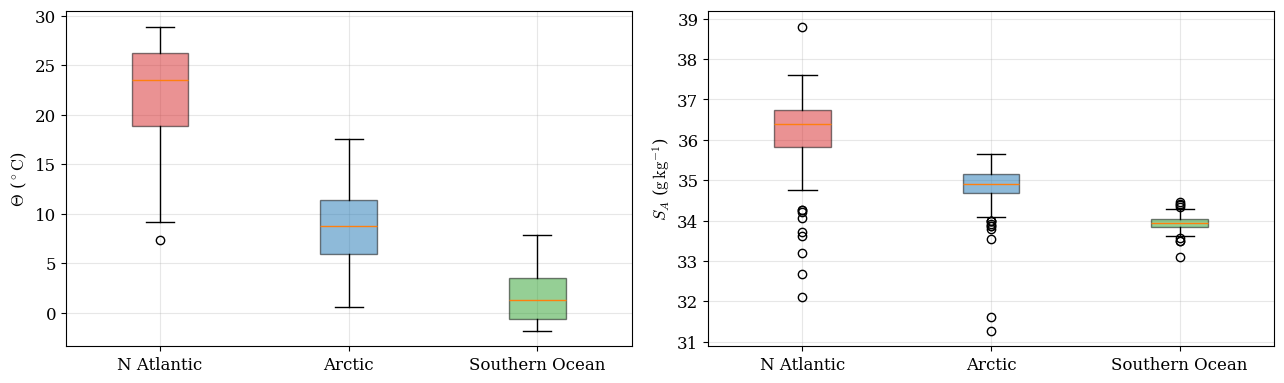

In [6]:
# box plots of temperature (left) and salinity (right) by basin
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
basin_boxplot(axs[0], "T")
basin_boxplot(axs[1], "S")
plt.tight_layout()

The North Atlantic samples are the warmest (mean 22.3 °C) and the saltiest (mean 36.23 g kg⁻¹). This is what I would expect if most of the floats sit in the subtropical gyre, where evaporation exceeds precipitation and the surface water is salty (Talley et al., 2011). The single maximum of 38.8 g kg⁻¹ is saltier than the open subtropical Atlantic usually gets, and would fit the Mediterranean if the basin mask includes it, but without positions I cannot check. The temperature distribution in the left panel has a long cold tail (skewness $-0.77$, minimum 7.3 °C), presumably from floats further north in the subpolar gyre.

The Southern Ocean samples are the coldest (mean 1.6 °C) and the freshest (mean 33.94 g kg⁻¹), and the salinity spread is very small: a standard deviation of 0.16 g kg⁻¹, about five times smaller than in the North Atlantic. My guess is that this is because the Antarctic Circumpolar Current carries water all the way round Antarctica, which would make the surface properties fairly uniform along a latitude band. The minimum temperature of $-1.86$ °C is at the freezing point of seawater (see the $TS$-diagram in §3), which is a reassuring sanity check on the data.

The `Arctic` label is a bit suspicious. A mean of 8.8 °C and a maximum of 17.6 °C are far too warm for the Arctic Ocean proper, whose surface sits near freezing for much of the year. The label probably includes the Nordic Seas or the subpolar region where warm Atlantic water flows north, though that is speculation without positions.

In the right panel, the North Atlantic and Arctic salinity distributions have a fresh tail (skewness $-1.37$ and $-3.2$, with values down to 32.1 and 31.3 g kg⁻¹), so in those two basins the median is higher than the mean. River runoff, sea ice melt and coastal water are plausible sources of these fresh samples. The Southern Ocean is close to symmetric by comparison (skewness $-0.38$, with 4 fresh and 4 salty outliers). Because of the tails, the median is the better summary of a "typical" salinity in the two northern basins.

## c) Correlation between temperature and salinity

Warm subtropical water tends to be salty and cold polar water fresh, so we might expect $\Theta$ and $S_A$ to be positively correlated. The cell below computes the Pearson (linear) correlation coefficient and, as a check against the influence of the fresh tails, the Spearman rank correlation (`scipy.stats.spearmanr`, which only cares about the ordering of the values), for each basin and for all data pooled.

In [7]:
# Pearson and Spearman correlation between T and S, per basin and pooled
groups = [(b, df[df["basin"] == b]) for b in basins] + [("all pooled", df)]
corr = pd.DataFrame({name: {"Pearson": stats.pearsonr(g["T"], g["S"])[0],
                            "Spearman": stats.spearmanr(g["T"], g["S"])[0]}
                     for name, g in groups})

# North Atlantic again, without its 10 salinity outliers (1.5 IQR rule, as in the box plots)
na = df[df["basin"] == "N_Atlantic"]
q1, q3 = na["S"].quantile([0.25, 0.75])
na_in = na[na["S"].between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))]
corr["N_Atlantic, no S outliers"] = [stats.pearsonr(na_in["T"], na_in["S"])[0],
                                     stats.spearmanr(na_in["T"], na_in["S"])[0]]
corr.round(2)

,N_Atlantic,Arctic,Southern_Ocean,all pooled,"N_Atlantic, no S outliers"
Pearson,0.26,0.40,0.09,0.83,0.18
Spearman,0.07,0.46,0.06,0.84,0.07


Pooled together, the correlation is strong ($r = 0.83$), but within each basin it is much weaker. The pooled value mostly reflects the differences *between* basins (the North Atlantic is warm and salty, the Southern Ocean cold and fresh), not how $\Theta$ and $S_A$ vary together *within* any one of them. 

In the North Atlantic, the Pearson value of 0.26 drops to 0.07 for Spearman, which suggests the linear correlation is partly carried by a few extreme points. The obvious suspects are the fresh outliers in the salinity box plot, which are a mix of cold (7 to 13 °C) and warm (27 to 29 °C) samples; a box plot shows one variable at a time, so this is easier to see on the $TS$-diagram in §3a. Removing the 10 North Atlantic salinity outliers (last column of the table) only lowers Pearson to 0.18, while Spearman stays at 0.07, so the outliers explain less than half of the gap. Either way, the bulk of the North Atlantic data shows almost no monotonic relationship. The Arctic is the only basin with a moderate correlation in both measures (0.40 and 0.46), which would be consistent with mixing between warm, salty Atlantic-origin water and cold, fresh polar water. In the Southern Ocean both are below 0.1.

> NOTE: A small correlation coefficient means no *linear* (or, for Spearman, monotonic) relationship, not no relationship at all.

--------------------
<a id="sec3"></a>

# §3 Density

## a) $TS$-diagram with TEOS-10 isopycnals

To show where each basin sits in density, I evaluate $\sigma_0$ on a regular $(S_A, \Theta)$ grid with the provided routine and contour it (`contour` and `clabel`, as in *09_fun_with_maps.ipynb*), with the data on top. The lines of constant density are [**isopycnals**](https://en.wikipedia.org/wiki/Isopycnal). The dashed line is the surface freezing temperature from `gsw.CT_freezing`; seawater below it would be ice, so no data should sit below it.

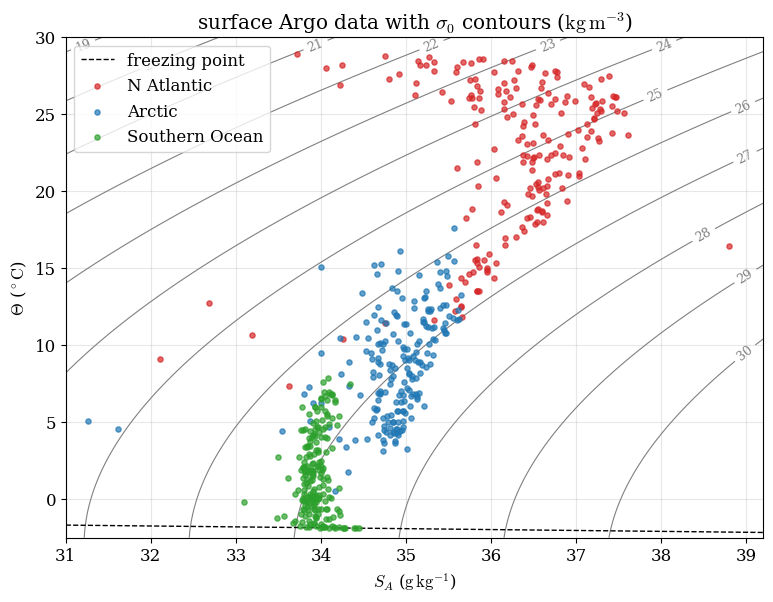

In [8]:
# TS-diagram with sigma_0 contours and the surface freezing line
S_grid, T_grid = np.meshgrid(np.linspace(31, 39.2, 165), np.linspace(-2.5, 30, 131))
sigma_grid = sigmai_dep(T_grid, S_grid)
S_line = np.linspace(31, 39.2, 50)

fig, ax = plt.subplots(figsize=(9, 6.5))
cs = ax.contour(S_grid, T_grid, sigma_grid, levels=np.arange(18, 31), colors="grey", linewidths=0.8)
ax.clabel(cs, fmt="%d", fontsize=9)
ax.plot(S_line, gsw.CT_freezing(S_line, 0, 0), "k--", lw=1, label="freezing point")
for b in basins:
    sub = df[df["basin"] == b]
    ax.scatter(sub["S"], sub["T"], s=14, color=colours[b], alpha=0.7, label=b.replace("_", " "), zorder=3)
ax.set_xlabel(labels["S"])
ax.set_ylabel(labels["T"])
ax.set_xlim([31, 39.2])
ax.set_ylim([-2.5, 30])
ax.set_title(r"surface Argo data with $\sigma_0$ contours ($\mathrm{kg\,m^{-3}}$)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3);

The three basins form largely separate clouds, and they are separated mostly in the vertical (temperature) direction. The isopycnals are curved: near freezing they are steep, so moving up or down in $\Theta$ crosses very few contours, while at high temperature they are much flatter and a few degrees of $\Theta$ crosses several of them. This curvature is the nonlinearity of the equation of state, and it is the reason why the answer to "temperature or salinity?" in §4 might be expected to depend on the basin.

In density terms, the Arctic (blue) and Southern Ocean (green) clouds lie in the same band of roughly 26 to 27.5 kg m⁻³, even though they barely overlap in $\Theta$ or $S_A$. The colder Southern Ocean water would be denser if it were not also fresher. The North Atlantic (red) spans about 21 to 28 kg m⁻³, with the lightest points being warm and fresh (e.g. 28.9 °C at 33.7 g kg⁻¹), perhaps tropical rainfall or river outflow, who knows. At the other end, the densest sample in the whole dataset ($\sigma_0 = 28.4$ kg m⁻³) is the 38.8 g kg⁻¹ North Atlantic point from §2b, at 16.5 °C: salty enough to be denser than even the near-freezing Southern Ocean water, which fits the Mediterranean suggestion. The coldest Southern Ocean points sit right on the dashed freezing line, as noted in §2.

> NOTE: Because the isopycnals are curved, mixing two water parcels of equal density but different $\Theta$ and $S_A$ gives water that is *denser* than either, a process known as [cabbeling](https://en.wikipedia.org/wiki/Cabbeling). On this diagram it shows up as the straight mixing line between two points on the same isopycnal sitting on the dense side of that isopycnal.

## b) Density statistics by basin

basin,N_Atlantic,Arctic,Southern_Ocean
mean,24.82,26.87,26.98
median,24.95,26.97,27.00
std,1.36,0.54,0.23
min,21.04,24.59,26.44
max,28.40,27.74,27.61
skew,-0.36,-1.14,-0.00


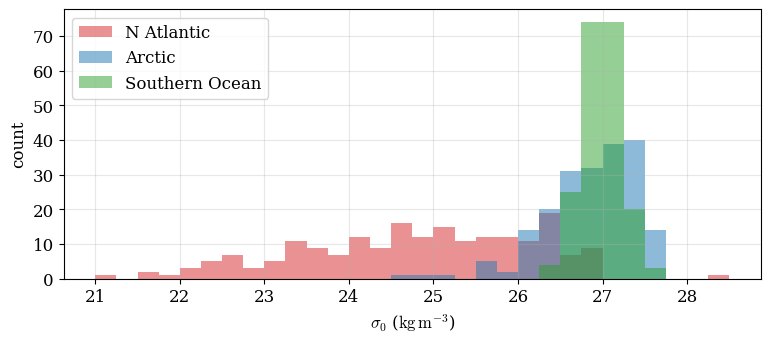

In [9]:
# summary statistics and histograms of sigma_0 by basin
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(21, 28.75, 0.25)
for b in basins:
    ax.hist(df.loc[df["basin"] == b, "sigma"], bins=bins, color=colours[b], alpha=0.5, label=b.replace("_", " "))
ax.set_xlabel(labels["sigma"])
ax.set_ylabel("count")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

stats_table("sigma")

The North Atlantic is the saltiest basin but the least dense, with a mean $\sigma_0$ of 24.82 kg m⁻³, about 2 kg m⁻³ lighter than the other two. It also has by far the widest spread (standard deviation 1.36 kg m⁻³), consistent with its wide spread in $\Theta$ where the isopycnals are flat. The Southern Ocean distribution is narrow and symmetric (standard deviation 0.23 kg m⁻³, skewness 0.00), while the Arctic one has a light tail (skewness $-1.14$) that, judging from §2, comes from the fresh outliers.

The Arctic and Southern Ocean means (26.87 and 26.98 kg m⁻³) are close enough that it is worth asking whether these two samples differ in density at all. "Differ" can mean different things here: a different spread, a different mean, or one basin's water tending to be denser than the other's. I test the last two separately, at a significance level of $\alpha_s = 0.05$ chosen in advance. A **Welch $t$-test** has $H_0$: the two basins have the same mean $\sigma_0$. A **Mann-Whitney U test** has $H_0$: neither basin's water tends to be denser than the other's, i.e. a randomly picked Arctic sample is as likely to be denser than a randomly picked Southern Ocean sample as the other way round. Following *06_statistical_tests.ipynb*, the cell below first checks normality (Shapiro-Wilk) and equality of variances (Levene), to see which assumptions hold.

In [10]:
# Arctic vs Southern Ocean density: check assumptions, then test
sig_A = df.loc[df["basin"] == "Arctic", "sigma"]
sig_SO = df.loc[df["basin"] == "Southern_Ocean", "sigma"]
print(f"Shapiro-Wilk p-value, Arctic        : {stats.shapiro(sig_A).pvalue:.2e}")
print(f"Shapiro-Wilk p-value, Southern Ocean: {stats.shapiro(sig_SO).pvalue:.2e}")
print(f"Levene p-value                      : {stats.levene(sig_A, sig_SO).pvalue:.2e}")

U, p_U = stats.mannwhitneyu(sig_A, sig_SO)
t, p_t = stats.ttest_ind(sig_A, sig_SO, equal_var=False)
print(f"\nMann-Whitney U = {U:.0f}, p = {p_U:.4f}")
print(f"(Welch t = {t:.2f}, p = {p_t:.4f})")
print(f"difference in means  : {sig_A.mean() - sig_SO.mean():.3f} kg/m^3")
print(f"difference in medians: {sig_A.median() - sig_SO.median():.3f} kg/m^3")
print(f"P(Arctic denser)     : {U / (len(sig_A) * len(sig_SO)):.2f}")
print(f"IQR Arctic, S Ocean  : {stats.iqr(sig_A):.2f}, {stats.iqr(sig_SO):.2f} kg/m^3")
print(f"Brunner-Munzel p     : {stats.brunnermunzel(sig_A, sig_SO).pvalue:.2f}")

Shapiro-Wilk p-value, Arctic        : 1.90e-08
Shapiro-Wilk p-value, Southern Ocean: 5.05e-01
Levene p-value                      : 6.02e-16

Mann-Whitney U = 18748, p = 0.2790
(Welch t = -2.84, p = 0.0049)
difference in means  : -0.117 kg/m^3
difference in medians: -0.028 kg/m^3
P(Arctic denser)     : 0.47
IQR Arctic, S Ocean  : 0.71, 0.31 kg/m^3
Brunner-Munzel p     : 0.30


The Arctic sample is not normal (Shapiro-Wilk $p \approx 2 \times 10^{-8}$) and the variances differ (Levene $p \approx 6 \times 10^{-16}$), so the two distributions are *not* the same: the Arctic one is more than twice as spread out. The unequal variances are why I use Welch's $t$-test rather than the standard one, and with 200 samples per basin the [central limit theorem](https://en.wikipedia.org/wiki/Central_limit_theorem) makes the sample *means* close to normally distributed even though the data is not.

Welch gives $t = -2.84$ and $p = 0.005$, so we reject equal means: the Arctic mean is 0.12 kg m⁻³ lower. Mann-Whitney gives $p = 0.279$, so we fail to reject its $H_0$. As an effect size, $U/(200 \times 200) = 0.47$ is the probability that a random Arctic sample is denser than a random Southern Ocean one, close to the 0.5 that $H_0$ describes.

Both results stand, because they answer different questions, and the banana skin would be to report only one. The gap between the *means* comes from the tail: a few fresh, light Arctic samples pull the Arctic mean down, while the ranks, and the medians (only 0.03 kg m⁻³ apart), barely notice them. The *spread* is a different matter: the Arctic values are wider everywhere, not just in the tail, with an interquartile range of 0.71 against 0.31 kg m⁻³. So the two basins have a similar centre but clearly different distributions. The differences in centre are small in practical terms: 0.12 kg m⁻³ is the density change from roughly 0.8 °C of warming in Arctic water, and 0.03 kg m⁻³ from about 0.2 °C (using the $\alpha$ values from §4).

> NOTE: Mann-Whitney only tests equal medians when the two distributions have the same shape, which they do not here, and its $p$-value is then only approximate. As a check, the Brunner-Munzel test (`stats.brunnermunzel`), a version of Mann-Whitney designed for unequal spreads, gives $p = 0.30$, the same conclusion.

--------------------
<a id="sec4"></a>

# §4 Temperature or salinity

In §3b the North Atlantic came out as the saltiest basin but also the least dense. Its high salinity on its own would make it the densest basin, so its much higher temperature (about 20 °C warmer than the Southern Ocean on average) must more than make up for it: temperature is what sets the North Atlantic apart from the two colder basins. Between the Arctic and the Southern Ocean the picture is different. As noted in §3a, the colder Southern Ocean water would be denser if it were not also fresher, and part a) below shows that the two effects almost cancel. The main question here is which variable controls the density variations *within* each basin. Linearising the equation of state around a reference state gives

$$
\delta\sigma_0 \approx \rho \left( -\alpha\, \delta\Theta + \beta\, \delta S_A \right), \qquad
    \alpha = -\frac{1}{\rho}\frac{\partial \rho}{\partial \Theta}, \qquad
    \beta = \frac{1}{\rho}\frac{\partial \rho}{\partial S_A},
$$

where $\alpha$ is the **thermal expansion coefficient** (in °C⁻¹) and $\beta$ the **haline contraction coefficient** (in kg g⁻¹). How much each variable contributes depends on two things: how sensitive density is to it ($\alpha$ or $\beta$), and how much it actually varies in the basin. I quantify this in two ways.

## a) Holding one variable fixed

For each basin I recompute $\sigma_0$ twice: once with $\Theta$ varying but $S_A$ fixed at the basin mean (the "T only" spread), and once the other way round (the "S only" spread). The ratio of the two standard deviations then says which variable matters more. This uses the full nonlinear equation of state, with no linearisation.

In [11]:
# std of sigma_0 with only T varying, only S varying, and both varying
rows = {}
for b in basins:
    sub = df[df["basin"] == b]
    rows[b] = {"std (both)": sub["sigma"].std(),
               "std (T only)": np.std(sigmai_dep(sub["T"], sub["S"].mean()), ddof=1),
               "std (S only)": np.std(sigmai_dep(sub["T"].mean(), sub["S"]), ddof=1),
               "r(T, S)": stats.pearsonr(sub["T"], sub["S"])[0]}
hold = pd.DataFrame(rows).T
hold["ratio T/S"] = hold["std (T only)"] / hold["std (S only)"]
sT, sS = hold["std (T only)"], hold["std (S only)"]
hold["std (formula)"] = np.sqrt(sT**2 + sS**2 - 2 * sT * sS * hold["r(T, S)"])

# same idea between basins: move T (or S) from one basin mean to the other, keep the other fixed
mean = df.groupby("basin")[["T", "S"]].mean()
pairs = {}
for x, y in [("N_Atlantic", "Southern_Ocean"), ("N_Atlantic", "Arctic"), ("Arctic", "Southern_Ocean")]:
    (Tx, Sx), (Ty, Sy) = mean.loc[x], mean.loc[y]
    pairs[f"{x} minus {y}"] = {"due to T": sigmai_dep(Tx, Sy) - sigmai_dep(Ty, Sy),
                               "due to S": sigmai_dep(Ty, Sx) - sigmai_dep(Ty, Sy),
                               "net": sigmai_dep(Tx, Sx) - sigmai_dep(Ty, Sy)}
display(hold.round(3), pd.DataFrame(pairs).T.round(2))

,std (both),std (T only),std (S only),"r(T, S)",ratio T/S,std (formula)
N_Atlantic,1.358,1.343,0.648,0.262,2.071,1.330
Arctic,0.538,0.548,0.398,0.404,1.375,0.531
Southern_Ocean,0.232,0.214,0.129,0.091,1.663,0.240


,due to T,due to S,net
N_Atlantic minus Southern_Ocean,-3.81,1.83,-2.1
N_Atlantic minus Arctic,-3.02,1.06,-2.0
Arctic minus Southern_Ocean,-0.82,0.74,-0.1


In all three basins the temperature-only spread is the larger one: by a factor of about 2.1 in the North Atlantic, 1.7 in the Southern Ocean and 1.4 in the Arctic.

The two separate spreads do not simply add in quadrature, because $\Theta$ and $S_A$ are correlated. Warm water tends to also be salty, and the two push density in opposite directions, so the correlation enters with a minus sign: $s^2 \approx s_\Theta^2 + s_S^2 - 2r\,s_\Theta s_S$, where $s$ is the full spread, $s_\Theta$ and $s_S$ are the "T only" and "S only" spreads, and $r$ is the Pearson correlation from §2c. This reproduces the actual spread to within 0.03 kg m⁻³ in all three basins ("std (formula)" against "std (both)"). The reduction, known as **density compensation**, is largest in the Arctic, where the correlation is strongest (0.40), and smallest in the Southern Ocean (0.09).

The second table applies the same idea *between* basins, using the basin means. The North Atlantic's warmth makes it 3.8 kg m⁻³ lighter than the Southern Ocean while its salinity makes it 1.8 kg m⁻³ denser, a net 2.1 kg m⁻³ lighter, and the comparison with the Arctic looks similar ($-3.0$ against $+1.1$). Between the Arctic and the Southern Ocean, the temperature and salinity effects ($-0.8$ and $+0.7$) almost cancel, which is why those two basins ended up with such similar densities in §3b.

## b) Thermal expansion and haline contraction coefficients

To see *why* the ratio differs between basins, I compute $\alpha$ and $\beta$ at every data point with centred finite differences on the provided routine, and cross-check them against `gsw.alpha` and `gsw.beta`.

max rel. diff from gsw: sigma0 1.0e-14, alpha 6.0e-09, beta 2.5e-10


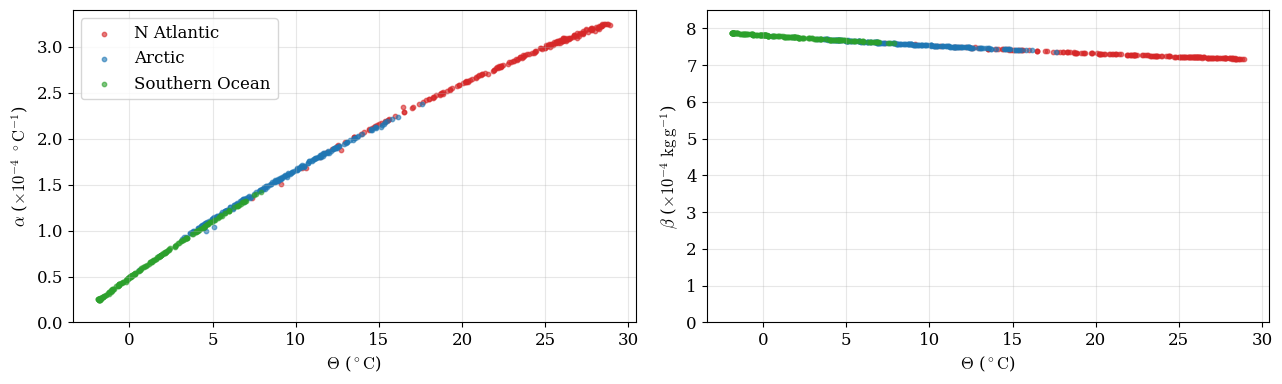

In [12]:
# alpha and beta by centred finite differences, checked against gsw
d = 1e-3
rho = 1000 + df["sigma"]
df["alpha"] = -(sigmai_dep(df["T"] + d, df["S"]) - sigmai_dep(df["T"] - d, df["S"])) / (2 * d * rho)
df["beta"] = (sigmai_dep(df["T"], df["S"] + d) - sigmai_dep(df["T"], df["S"] - d)) / (2 * d * rho)

rel_err = lambda a, b: np.max(np.abs(a - b) / np.abs(b))
print(f"max rel. diff from gsw: sigma0 {rel_err(df['sigma'], gsw.sigma0(df['S'], df['T'])):.1e}, "
      f"alpha {rel_err(df['alpha'], gsw.alpha(df['S'], df['T'], 0)):.1e}, "
      f"beta {rel_err(df['beta'], gsw.beta(df['S'], df['T'], 0)):.1e}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for b in basins:
    sub = df[df["basin"] == b]
    axs[0].scatter(sub["T"], sub["alpha"] * 1e4, s=10, color=colours[b], alpha=0.6, label=b.replace("_", " "))
    axs[1].scatter(sub["T"], sub["beta"] * 1e4, s=10, color=colours[b], alpha=0.6)
axs[0].set_ylabel(r"$\alpha$ ($\times 10^{-4}$ $^\circ\mathrm{C}^{-1}$)")
axs[1].set_ylabel(r"$\beta$ ($\times 10^{-4}$ $\mathrm{kg\,g^{-1}}$)")
axs[1].set_ylim([0, 8.5])
for ax in axs:
    ax.set_xlabel(labels["T"])
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout()

The finite-difference values agree with `gsw` to within a relative difference of $6 \times 10^{-9}$, so the provided routine and the official package are consistent. In the left panel, $\alpha$ increases more than tenfold, from about $0.25 \times 10^{-4}$ °C⁻¹ in the coldest Southern Ocean water to $3.2 \times 10^{-4}$ °C⁻¹ in the warmest North Atlantic water, and the points from all three basins fall on a single curve, so it depends almost only on $\Theta$. In the right panel, $\beta$ only varies between about 7.2 and $7.9 \times 10^{-4}$ kg g⁻¹, roughly 10%. This is the curvature of the isopycnals in §3a in another form.

In [13]:
# linearised version of the ratio in part a), alpha and beta shown in units of 1e-4
lin = df.groupby("basin").agg(alpha=("alpha", "mean"), beta=("beta", "mean"), std_T=("T", "std"), std_S=("S", "std")).loc[basins]
lin["alpha std_T / beta std_S"] = lin["alpha"] * lin["std_T"] / (lin["beta"] * lin["std_S"])
lin["ratio from a)"] = hold["ratio T/S"]
lin[["alpha", "beta"]] *= 1e4
lin.round(2)

,alpha,beta,std_T,std_S,alpha std_T / beta std_S,ratio from a)
basin,,,,,,
N_Atlantic,2.76,7.28,4.99,0.87,2.18,2.07
Arctic,1.52,7.57,3.40,0.51,1.33,1.37
Southern_Ocean,0.69,7.77,2.64,0.16,1.45,1.66


The linearised ratio $\alpha\,\mathrm{std}(\Theta) / \beta\,\mathrm{std}(S_A)$, which is essentially the [density ratio](https://en.wikipedia.org/wiki/Double_diffusive_convection) built from the basin spreads, agrees with the hold-fixed ratio from part a) to within about 15%, so the two methods tell the same story.

Easy right? Cold water, small $\alpha$, so salinity should control density in the polar basins. High-latitude oceans are indeed often described as "beta oceans", where salinity sets the stratification, as opposed to the temperature-stratified "alpha oceans" at lower latitudes (Carmack, 2007). This data says otherwise. In the Southern Ocean the basin-mean $\alpha$ is about four times smaller than in the North Atlantic, but the salinity spread is also tiny (0.16 g kg⁻¹), so temperature still wins by a factor of 1.4 to 1.7 depending on the method. The two statements are not actually in conflict. The alpha/beta classification is about *vertical* stratification of the upper ocean, while this dataset only has *horizontal* (surface) variability, and a surface-only dataset cannot test it.

-------------------------
<a id="sec5"></a>

# §5 Conclusion

This notebook described 600 surface Argo measurements of Conservative Temperature and Absolute Salinity, 200 each from the North Atlantic, the "Arctic" and the Southern Ocean, together with their TEOS-10 potential density anomaly $\sigma_0$. The main findings are:

* **North Atlantic**: warmest and saltiest (means 22.3 °C, 36.23 g kg⁻¹), but the lightest ($\sigma_0 \approx 24.8$ kg m⁻³) and with the widest density spread. Temperature controls density variations by a factor of about 2.
* **Southern Ocean**: coldest and freshest (1.6 °C, 33.94 g kg⁻¹), with very uniform salinity and data reaching the freezing point. Its density ($\sigma_0 \approx 27.0$ kg m⁻³) is still controlled more by temperature than salinity (factor 1.4 to 1.7), despite $\alpha$ being four times smaller than in the North Atlantic.
* **"Arctic"**: intermediate (8.8 °C, 34.87 g kg⁻¹), too warm to be the Arctic Ocean proper, with a strong fresh tail and the clearest $\Theta$-$S_A$ correlation. Temperature and salinity effects partly compensate, and temperature dominates by only a factor of about 1.4.
* The Arctic and Southern Ocean densities have a similar centre (medians differ by 0.03 kg m⁻³, Mann-Whitney $p = 0.28$), although the Arctic mean is 0.12 kg m⁻³ lower (Welch $p = 0.005$) because of a few fresh, light samples, and the Arctic densities are more than twice as spread out, in the bulk as well as the tail. The two basins get there from quite different $(\Theta, S_A)$, with the temperature and salinity differences almost cancelling.


The main limitations are that there are no positions or dates, so the interpretations involving the subtropical gyre, the Circumpolar Current or the Nordic Seas are plausible but unverified, and any seasonal signal is mixed in; and that the data is a random subset of 200 points per basin, so the tails in particular are not well sampled. The question of whether temperature or salinity sets the density is also only answered for horizontal surface variability here, which is not the same as the vertical stratification question that the alpha/beta ocean distinction (Carmack, 2007) is about.

Things that could be done next, which I have not attempted here:

1) **Map the samples.** The original `zarr` file (or the [`argopy`](https://argopy.readthedocs.io/en/latest/) package) has positions and dates. Plotting the 600 points on a map would immediately show what the "Arctic" label covers and whether the fresh outliers are coastal, and splitting by month would separate out the seasonal cycle.

2) **Use the full profiles.** With profiles down to 2000 dbar, the buoyancy frequency $N^2$ could be split into its $\alpha\,\partial_z\Theta$ and $\beta\,\partial_z S_A$ parts, which would test the alpha/beta ocean idea properly in each basin.

-------------
<a id="bib"></a>

# Bibliography

* Argo (2000). Argo float data and metadata from Global Data Assembly Centre (Argo GDAC). *SEANOE*. https://doi.org/10.17882/42182
* Carmack, E. C. (2007). The alpha/beta ocean distinction: a perspective on freshwater fluxes, convection, nutrients and productivity in high-latitude seas. *Deep-Sea Research II*, **54**(23-26), 2578-2598.
* IOC, SCOR and IAPSO (2010). *The international thermodynamic equation of seawater 2010: calculation and use of thermodynamic properties*. Intergovernmental Oceanographic Commission, Manuals and Guides No. 56, UNESCO.
* McDougall, T. J. and Barker, P. M. (2011). *Getting started with TEOS-10 and the Gibbs Seawater (GSW) Oceanographic Toolbox*. SCOR/IAPSO WG127.
* Roemmich, D., Johnson, G. C., Riser, S., Davis, R., Gilson, J., Owens, W. B., Garzoli, S. L., Schmid, C. and Ignaszewski, M. (2009). The Argo Program: observing the global ocean with profiling floats. *Oceanography*, **22**(2), 34-43.
* Roquet, F., Madec, G., McDougall, T. J. and Barker, P. M. (2015). Accurate polynomial expressions for the density and specific volume of seawater using the TEOS-10 standard. *Ocean Modelling*, **90**, 29-43.
* Talley, L. D., Pickard, G. L., Emery, W. J. and Swift, J. H. (2011). *Descriptive Physical Oceanography: An Introduction* (6th ed.). Academic Press.
* Wong, A. P. S., et al. (2020). Argo data 1999-2019: two million temperature-salinity profiles and subsurface velocity observations from a global array of profiling floats. *Frontiers in Marine Science*, **7**, 700.
* Course notebooks: *02_reading_data_basic_manipulations.ipynb*, *06_statistical_tests.ipynb*, *09_fun_with_maps.ipynb*, *bonus_some_machine_learning.ipynb* (source of the data), and the assignment brief (source of `sigmai_dep`).